In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import os
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
data = []
labels = []
categories = ['glioma', 'meningioma', 'pituitary', 'notumor']
data_dir = '/content/drive/MyDrive/agyikepek_4_osztaly/Training'

for category in categories:
    path = os.path.join(data_dir, category)
    class_num = categories.index(category)
    for img in os.listdir(path):
        try:
            img_array = cv2.imread(os.path.join(path, img), cv2.IMREAD_COLOR)
            resized_img = cv2.resize(img_array, (128, 128))
            data.append(resized_img)
            labels.append(class_num)
        except Exception as e:
            pass


In [4]:
data = np.array(data)
labels = np.array(labels)


In [5]:
data = data / 255.0


In [6]:
labels = to_categorical(labels, num_classes=4)


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    data, labels, test_size=0.15, random_state=42, stratify=labels)


Raw feature dim: 4096
PCA feature dim: 50

>> Training RandomForest...
RandomForest — Test Accuracy: 0.8333
              precision    recall  f1-score   support

      glioma       0.79      0.76      0.78       198
  meningioma       0.77      0.69      0.73       201
   pituitary       0.82      0.95      0.88       202
     notumor       0.93      0.92      0.92       239

    accuracy                           0.83       840
   macro avg       0.83      0.83      0.83       840
weighted avg       0.83      0.83      0.83       840


>> Training LogisticRegression...
LogisticRegression — Test Accuracy: 0.7738
              precision    recall  f1-score   support

      glioma       0.72      0.76      0.74       198
  meningioma       0.65      0.57      0.61       201
   pituitary       0.81      0.93      0.87       202
     notumor       0.89      0.82      0.85       239

    accuracy                           0.77       840
   macro avg       0.77      0.77      0.77       840

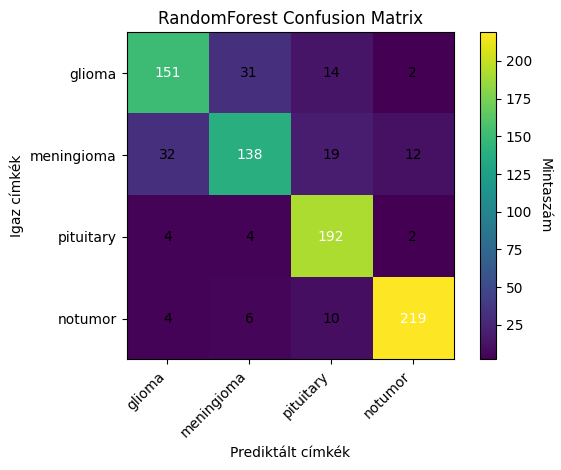

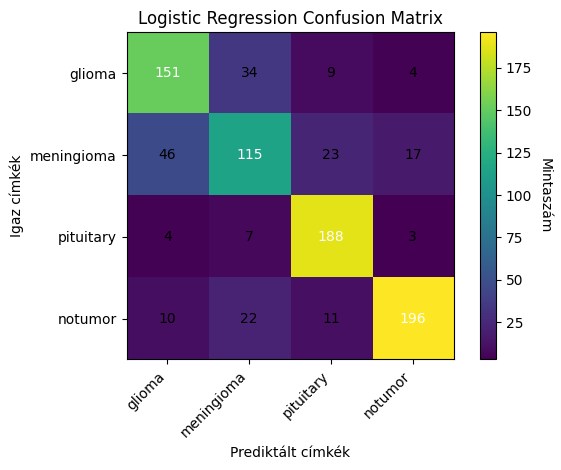

In [11]:
import numpy as np
import cv2
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# --- 0) One-hot -> int címkék
y_train_int = np.argmax(y_train, axis=1)
y_test_int  = np.argmax(y_test,  axis=1)

# --- 1) Szürke, 64×64, flatten
def preprocess_gray64(imgs):
    out = []
    for img in imgs:
        # img: [0,1] float, shape=(128,128,3)
        g = cv2.cvtColor((img*255).astype(np.uint8), cv2.COLOR_BGR2GRAY)
        small = cv2.resize(g, (64,64), interpolation=cv2.INTER_AREA)
        out.append(small.flatten()/255.0)
    return np.array(out)

X_tr_small = preprocess_gray64(X_train)
X_te_small = preprocess_gray64(X_test)

print("Raw feature dim:", X_tr_small.shape[1])  # 4096

# --- 2) Erős PCA (4096 -> 50)
pca = PCA(n_components=50, random_state=42)
X_tr_pca = pca.fit_transform(X_tr_small)
X_te_pca = pca.transform(X_te_small)
print("PCA feature dim:", X_tr_pca.shape[1])     # 50

# modell-lista: (név, estimator)
models = [
    ("RandomForest", RandomForestClassifier(
        n_estimators=50,    # kevesebb fa
        max_depth=10,       # sekélyebb fák
        n_jobs=-1,
        random_state=42)),
    ("LogisticRegression",
     # skalázó + LR pipeline nélkül: skálázunk manuálisan
     LogisticRegression(
        penalty='l2',
        C=1.0,
        solver='saga',
        max_iter=500,
        n_jobs=-1,
        random_state=42))
]

results = {}

# --- 3) Skálázás logisztikus regresszióhoz
scaler = StandardScaler()
X_tr_lr = scaler.fit_transform(X_tr_pca)
X_te_lr = scaler.transform(X_te_pca)

for name, model in models:
    print(f"\n>> Training {name}...")
    if name == "LogisticRegression":
        model.fit(X_tr_lr, y_train_int)
        X_tr_used, X_te_used = X_tr_lr, X_te_lr
    else:
        model.fit(X_tr_pca, y_train_int)
        X_tr_used, X_te_used = X_tr_pca, X_te_pca

    # --- 4) Kiértékelés
    y_pred = model.predict(X_te_used)
    acc = accuracy_score(y_test_int, y_pred)
    cm  = confusion_matrix(y_test_int, y_pred)

    print(f"{name} — Test Accuracy: {acc:.4f}")
    print(classification_report(y_test_int, y_pred, target_names=categories))

    results[name] = {"acc": acc, "cm": cm}

# RandomForest konfúziós mátrix ábrája
cm_rf = results["RandomForest"]["cm"]

fig = plt.figure()
ax = fig.add_subplot(111)
im = ax.imshow(cm_rf, interpolation='nearest')
cbar = fig.colorbar(im, ax=ax)
cbar.ax.set_ylabel('Mintaszám', rotation=-90, va="bottom")

ax.set_xticks(np.arange(len(categories)))
ax.set_yticks(np.arange(len(categories)))
ax.set_xticklabels(categories, rotation=45, ha="right")
ax.set_yticklabels(categories)
ax.set_ylabel('Igaz címkék')
ax.set_xlabel('Prediktált címkék')

thresh = cm_rf.max() / 2.
for i in range(cm_rf.shape[0]):
    for j in range(cm_rf.shape[1]):
        ax.text(j, i, format(cm_rf[i, j], 'd'),
                ha="center", va="center",
                color="white" if cm_rf[i, j] > thresh else "black")

plt.title('RandomForest Confusion Matrix')
plt.tight_layout()
plt.show()

# Logistic Regression konfúziós mátrix ábrája
cm_lr = results["LogisticRegression"]["cm"]

fig = plt.figure()
ax = fig.add_subplot(111)
im = ax.imshow(cm_lr, interpolation='nearest')
cbar = fig.colorbar(im, ax=ax)
cbar.ax.set_ylabel('Mintaszám', rotation=-90, va="bottom")

ax.set_xticks(np.arange(len(categories)))
ax.set_yticks(np.arange(len(categories)))
ax.set_xticklabels(categories, rotation=45, ha="right")
ax.set_yticklabels(categories)
ax.set_ylabel('Igaz címkék')
ax.set_xlabel('Prediktált címkék')

thresh = cm_lr.max() / 2.
for i in range(cm_lr.shape[0]):
    for j in range(cm_lr.shape[1]):
        ax.text(j, i, format(cm_lr[i, j], 'd'),
                ha="center", va="center",
                color="white" if cm_lr[i, j] > thresh else "black")

plt.title('Logistic Regression Confusion Matrix')
plt.tight_layout()
plt.show()

In [9]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.15, random_state=42, stratify=y_train)


In [10]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Flatten, Dropout,GlobalAveragePooling2D
from tensorflow.keras.applications.vgg16 import VGG16,preprocess_input
from tensorflow.keras.applications.efficientnet import EfficientNetB0
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.regularizers import l2
from tensorflow.keras.layers import BatchNormalization
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report

In [ ]:
datagen = ImageDataGenerator(
    rotation_range=20,
    horizontal_flip=True,
    zoom_range=0.2
)
datagen.fit(X_train)

In [ ]:
base_model = VGG16(weights='imagenet', include_top=False, input_shape=(128, 128, 3))
base_model.trainable = True
for layer in base_model.layers[:-2]:
    layer.trainable = False
base_model.summary()

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(512, activation='relu', kernel_regularizer=l2(0.001))(x)
x = BatchNormalization()(x)
x = Dropout(0.5)(x)
x = Dense(256, activation='relu')(x)
x = BatchNormalization()(x)
x = Dropout(0.2)(x)
predictions = Dense(4, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=predictions)
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
checkpoint = ModelCheckpoint('best_model.keras', monitor='val_loss', save_best_only=True)
history = model.fit(
    datagen.flow(X_train, y_train, batch_size=32),
    epochs=50,
    batch_size=32,
    validation_data=(X_val, y_val),
    callbacks=[early_stopping, checkpoint]
)
model.load_weights('best_model.keras')
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f'Test accuracy: {test_acc}')
y_pred = model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = np.argmax(y_test, axis=1)

print(classification_report(y_true, y_pred_classes, target_names=categories))

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 128, 128, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 128, 128, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 64, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 64, 64, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 32, 32, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 32, 32, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 32, 32, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 16, 16, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 16, 16, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 16, 16, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 8, 8, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 8, 8, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 8, 8, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 8, 8, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 4, 4, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 2,359,808 (9.00 MB)

 Non-trainable params: 12,354,880 (47.13 MB)

Epoch 1/50
127/127 ━━━━━━━━━━━━━━━━━━━━ 41s 237ms/step - accuracy: 0.6622 - loss: 1.3048 - val_accuracy: 0.6807 - val_loss: 1.9519
Epoch 2/50
127/127 ━━━━━━━━━━━━━━━━━━━━ 20s 158ms/step - accuracy: 0.8226 - loss: 0.7371 - val_accuracy: 0.7969 - val_loss: 0.9414
Epoch 3/50
127/127 ━━━━━━━━━━━━━━━━━━━━ 21s 166ms/step - accuracy: 0.8437 - loss: 0.6234 - val_accuracy: 0.8123 - val_loss: 0.7354
Epoch 4/50
127/127 ━━━━━━━━━━━━━━━━━━━━ 20s 157ms/step - accuracy: 0.8547 - loss: 0.5693 - val_accuracy: 0.8922 - val_loss: 0.4619
Epoch 5/50
127/127 ━━━━━━━━━━━━━━━━━━━━ 21s 163ms/step - accuracy: 0.8818 - loss: 0.4647 - val_accuracy: 0.8599 - val_loss: 0.5882
Epoch 6/50
127/127 ━━━━━━━━━━━━━━━━━━━━ 20s 155ms/step - accuracy: 0.8733 - loss: 0.4486 - val_accuracy: 0.8375 - val_loss: 0.5634
Epoch 7/50
127/127 ━━━━━━━━━━━━━━━━━━━━ 21s 162ms/step - accuracy: 0.8939 - loss: 0.3983 - val_accuracy: 0.7311 - val_loss: 0.7959
Epoch 8/50
127/127 ━━━━━━━━━━━━━━━━━━━━ 23s 179ms/step - accuracy: 0.8934 - loss: 0

In [ ]:
base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(128, 128, 3))
base_model.trainable = True
for layer in base_model.layers[:-2]:
    layer.trainable = False
base_model.summary()

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(512, activation='relu', kernel_regularizer=l2(0.001))(x)
x = BatchNormalization()(x)
x = Dropout(0.5)(x)
x = Dense(256, activation='relu')(x)
x = BatchNormalization()(x)
x = Dropout(0.2)(x)
predictions = Dense(4, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=predictions)
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
checkpoint = ModelCheckpoint('best_model.keras', monitor='val_loss', save_best_only=True)
history = model.fit(
    datagen.flow(X_train, y_train, batch_size=32),
    epochs=50,
    batch_size=32,
    validation_data=(X_val, y_val),
    callbacks=[early_stopping, checkpoint]
)
model.load_weights('best_model.keras')
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f'Test accuracy: {test_acc}')
y_pred = model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = np.argmax(y_test, axis=1)

print(classification_report(y_true, y_pred_classes, target_names=categories))

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "resnet50"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 134, 134,  │          0 │ input_layer_2[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 64, 64,    │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 64, 64,    │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 64, 64,    │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 66, 66,    │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 32, 32,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 32, 32,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 32, 32,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 32, 32,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 32, 32,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 32, 32,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 32, 32,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 32, 32,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 32, 32,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 32, 32,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 32, 32,    │      1,024 │ conv2_block1_3_c

 Total params: 23,587,712 (89.98 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 23,587,712 (89.98 MB)

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/50
127/127 ━━━━━━━━━━━━━━━━━━━━ 48s 268ms/step - accuracy: 0.5294 - loss: 1.5694 - val_accuracy: 0.3067 - val_loss: 1.3735
Epoch 2/50
127/127 ━━━━━━━━━━━━━━━━━━━━ 21s 154ms/step - accuracy: 0.6450 - loss: 0.9683 - val_accuracy: 0.5168 - val_loss: 1.1023
Epoch 3/50
127/127 ━━━━━━━━━━━━━━━━━━━━ 20s 155ms/step - accuracy: 0.6583 - loss: 0.8821 - val_accuracy: 0.5490 - val_loss: 1.1169
Epoch 4/50
127/127 ━━━━━━━━━━━━━━━━━━━━ 19s 151ms/step - accuracy: 0.6655 - loss: 0.8685 - val_accuracy: 0.4272 - val_loss: 2.0777
Epoch 5/50
127/127 ━━━━━━━━━━━━━━━━━━━━ 21s 162ms/step - accuracy: 0.6756 - loss: 0.8425 - val_accuracy: 0.6275 - val_loss: 0.8660
Epoch 6/50
127/127 ━━━━━━━━━━━━━━━━━━━━ 21s 163ms/step - accuracy: 0.6952 - loss: 0.8085 - val_accuracy: 0.6120 - val_loss: 1.0510
Epoch 7/50
127/127 ━━━━━━━━━━━━━━━━━━━━ 40s 157ms/step - accuracy: 0.7049 - loss: 0.7906 - val_accuracy: 0.7535 - val_loss: 0.7504
Epoch 8/50
127/127 ━━━━━━━━━━━━━━━━━━━━ 21s 166ms/step - accuracy: 0.7032 - loss: 0

In [ ]:
from tensorflow.keras.applications import DenseNet121

base_model = DenseNet121(weights='imagenet', include_top=False, input_shape=(128, 128, 3))
base_model.trainable = True
for layer in base_model.layers[:-8]:
    layer.trainable = False
base_model.summary()

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(512, activation='relu', kernel_regularizer=l2(0.001))(x)
x = BatchNormalization()(x)
x = Dropout(0.5)(x)
x = Dense(256, activation='relu', kernel_regularizer=l2(0.001))(x)
x = BatchNormalization()(x)
x = Dropout(0.2)(x)
x = Dense(128, activation='relu', kernel_regularizer=l2(0.001))(x)
x = BatchNormalization()(x)
x = Dropout(0.2)(x)
x = Dense(64, activation='relu', kernel_regularizer=l2(0.001))(x)
x = BatchNormalization()(x)
x = Dropout(0.2)(x)
x = Dense(32, activation='relu', kernel_regularizer=l2(0.001))(x)
x = BatchNormalization()(x)
x = Dropout(0.2)(x)
x = Dense(16, activation='relu', kernel_regularizer=l2(0.01))(x)
x = BatchNormalization()(x)
x = Dropout(0.2)(x)
predictions = Dense(4, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=predictions)
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

early_stopping = EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)
checkpoint = ModelCheckpoint('best_model.keras', monitor='val_loss', save_best_only=True)
history = model.fit(
    datagen.flow(X_train, y_train, batch_size=32),
    epochs=150,
    batch_size=32,
    validation_data=(X_val, y_val),
    callbacks=[early_stopping, checkpoint]
)
model.load_weights('best_model.keras')
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f'Test accuracy: {test_acc}')
y_pred = model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = np.argmax(y_test, axis=1)

print(classification_report(y_true, y_pred_classes, target_names=categories))

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "densenet121"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d      │ (None, 134, 134,  │          0 │ input_layer_3[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 64, 64,    │      9,408 │ zero_padding2d[0… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 64, 64,    │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 64, 64,    │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d_1    │ (None, 66, 66,    │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1               │ (None, 32, 32,    │          0 │ zero_padding2d_1… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 32, 32,    │        256 │ pool1[0][0]       │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_relu │ (None, 32, 32,    │          0 │ conv2_block1_0_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 32, 32,    │      8,192 │ conv2_block1_0_r… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 32, 32,    │        512 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 32, 32,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 32, 32,    │     36,864 │ conv2_block1_1_r… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_concat │ (None, 32, 32,    │          0 │ pool1[0][0],      │
│ (Concatenate)       │ 96)               │            │ conv2_block1_2_c… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_bn   │ (None, 32, 32,    │        384 │ conv2_block1_con… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_relu │ (None, 32, 32,    │          0 │ conv2_block2_0_b… │
│ (Activation)        │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_1_conv │ (None, 32, 32,    │     12,288 │ conv2_block2_0_r

 Total params: 7,037,504 (26.85 MB)

 Trainable params: 166,144 (649.00 KB)

 Non-trainable params: 6,871,360 (26.21 MB)

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/150
127/127 ━━━━━━━━━━━━━━━━━━━━ 102s 506ms/step - accuracy: 0.4496 - loss: 2.7186 - val_accuracy: 0.7171 - val_loss: 1.9041
Epoch 2/150
127/127 ━━━━━━━━━━━━━━━━━━━━ 22s 174ms/step - accuracy: 0.7447 - loss: 1.8568 - val_accuracy: 0.8249 - val_loss: 1.6556
Epoch 3/150
127/127 ━━━━━━━━━━━━━━━━━━━━ 41s 176ms/step - accuracy: 0.8072 - loss: 1.6660 - val_accuracy: 0.8683 - val_loss: 1.4526
Epoch 4/150
127/127 ━━━━━━━━━━━━━━━━━━━━ 41s 173ms/step - accuracy: 0.8424 - loss: 1.4970 - val_accuracy: 0.8165 - val_loss: 1.5040
Epoch 5/150
127/127 ━━━━━━━━━━━━━━━━━━━━ 22s 176ms/step - accuracy: 0.8541 - loss: 1.4187 - val_accuracy: 0.8824 - val_loss: 1.2840
Epoch 6/150
127/127 ━━━━━━━━━━━━━━━━━━━━ 39s 158ms/step - accuracy: 0.8808 - loss: 1.2855 - val_accuracy: 0.8375 - val_loss: 1.4181
Epoch 7/150
127/127 ━━━━━━━━━━━━━━━━━━━━ 22s 172ms/step - accuracy: 0.8977 - loss: 1.2000 - val_accuracy: 0.9006 - val_loss: 1.1137
Epoch 8/150
127/127 ━━━━━━━━━━━━━━━━━━━━ 23s 182ms/step - accuracy: 0.8916 

In [ ]:
from sklearn.metrics import classification_report

y_pred = model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = np.argmax(y_test, axis=1)

print(classification_report(y_true, y_pred_classes, target_names=categories))


27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step
              precision    recall  f1-score   support

      glioma       0.99      0.92      0.96       198
  meningioma       0.94      0.95      0.94       201
   pituitary       0.95      0.98      0.97       202
     notumor       0.97      1.00      0.98       239

    accuracy                           0.96       840
   macro avg       0.96      0.96      0.96       840
weighted avg       0.96      0.96      0.96       840



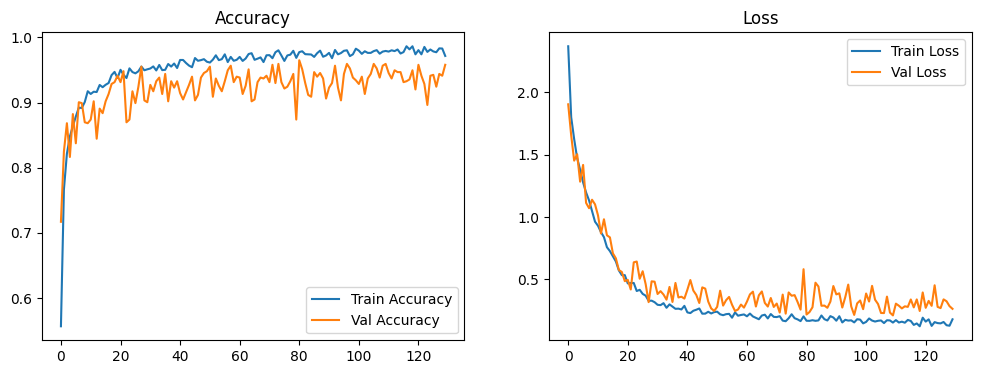

In [ ]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.legend()
plt.title('Accuracy')

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.legend()
plt.title('Loss')
plt.show()


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.5/52.5 kB 2.9 MB/s eta 0:00:00
1/1 ━━━━━━━━━━━━━━━━━━━━ 8s 8s/step


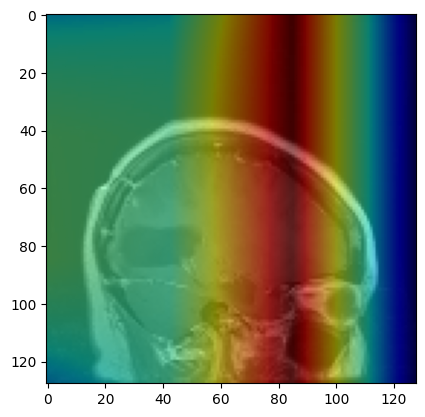

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step


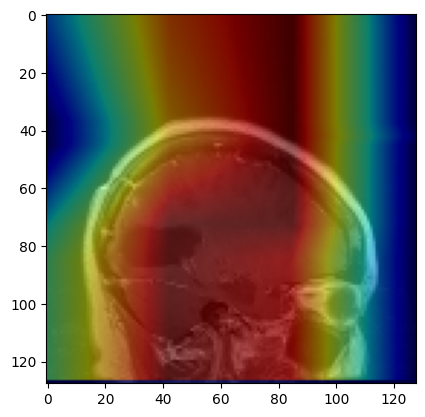

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step


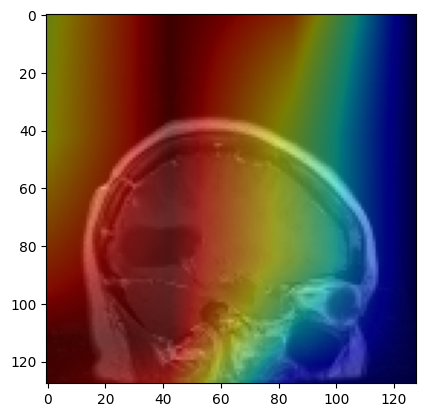

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step


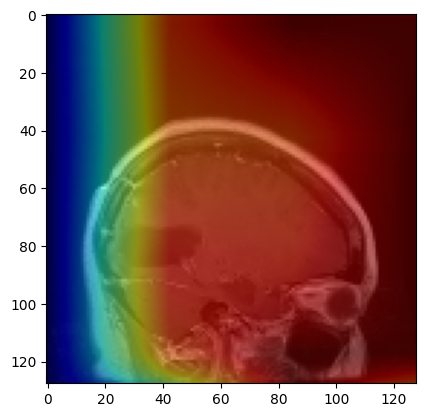

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step


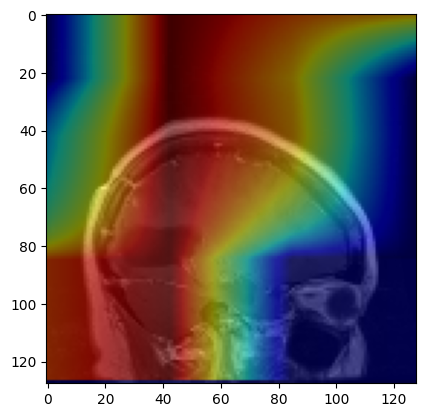

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step


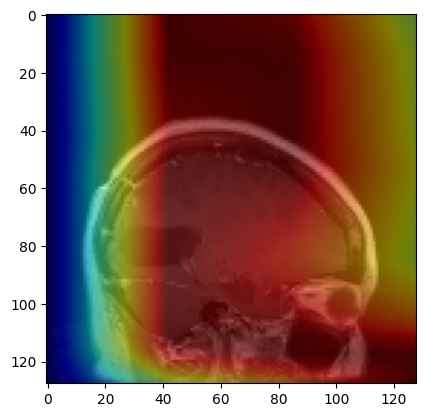

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step


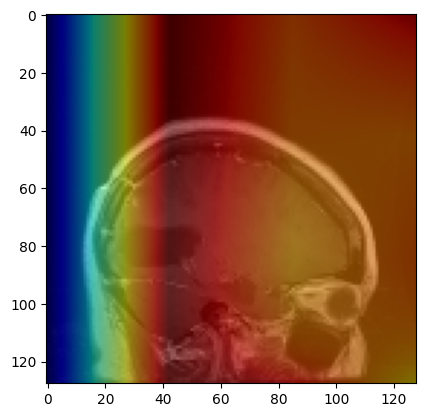

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step


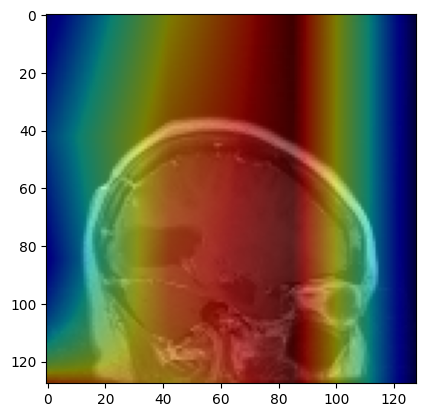

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step


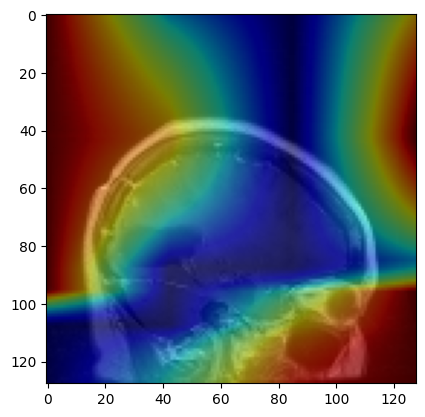

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step


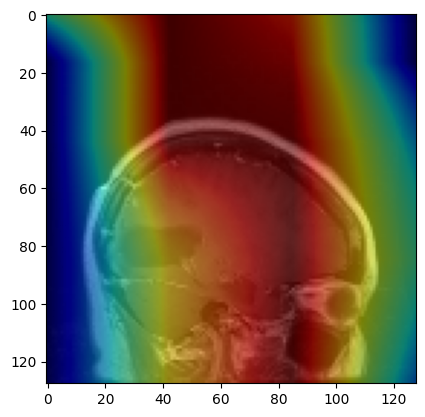

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step


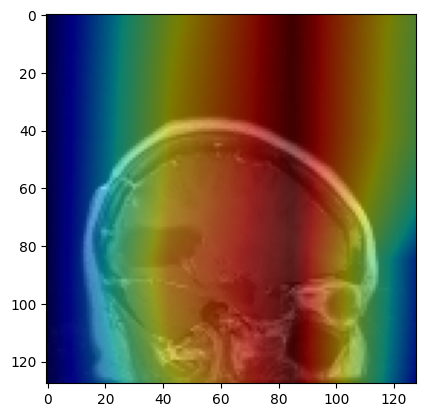

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step


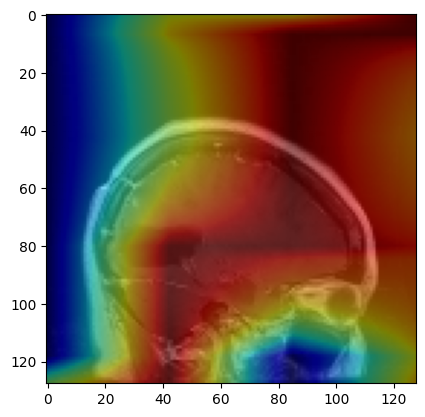

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step


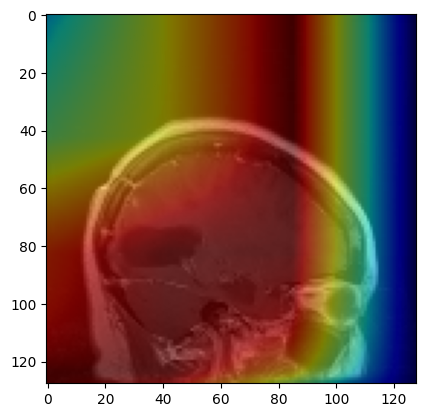

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step


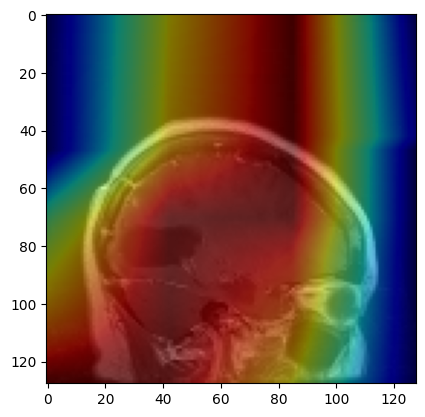

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step


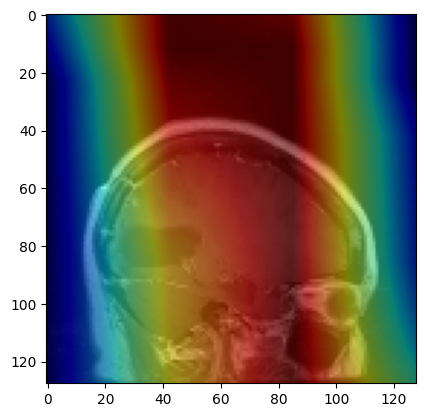

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step


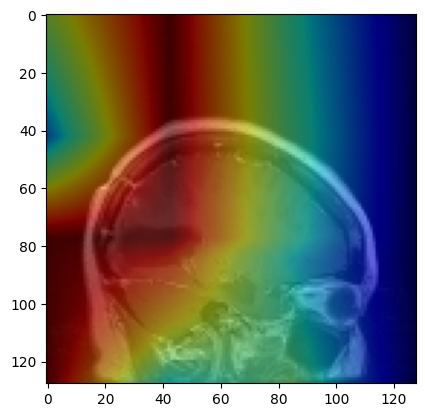

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step


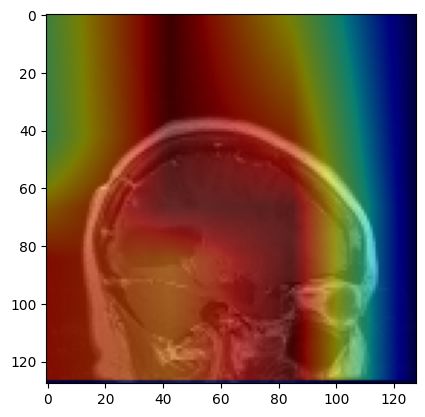

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step


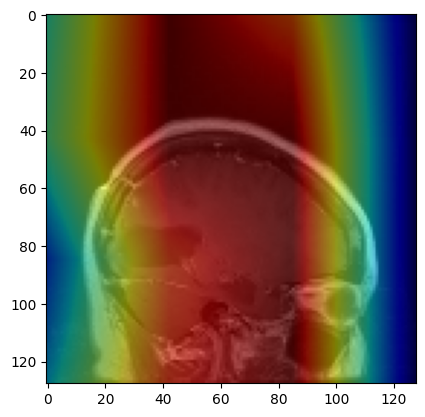

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step


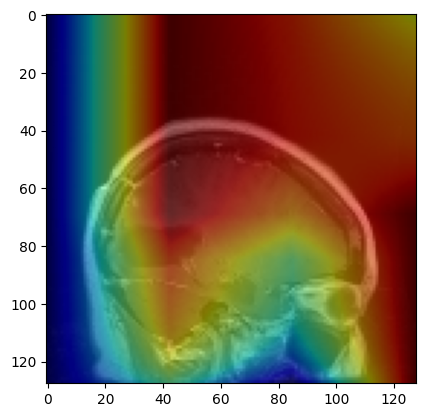

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step


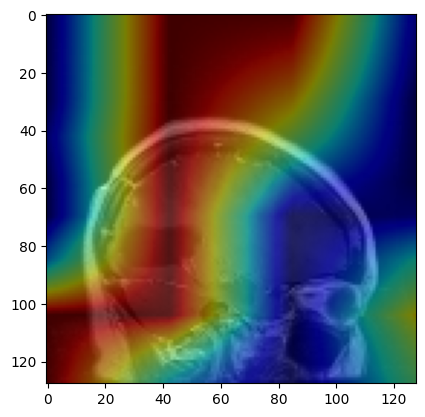

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step


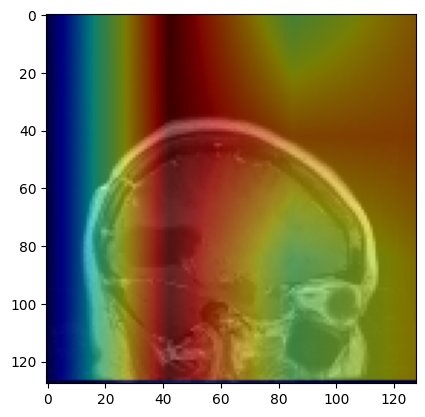

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step


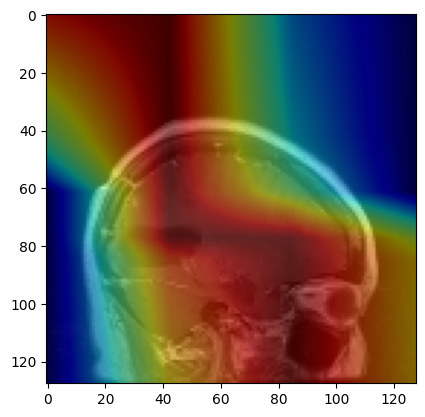

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step


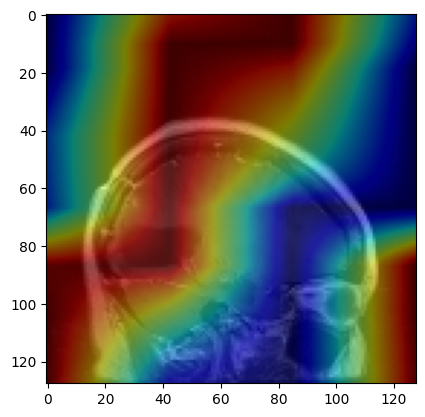

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step


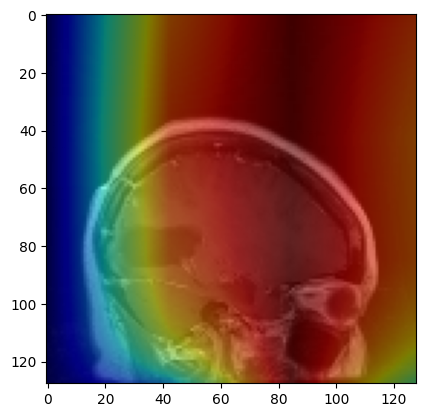

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step


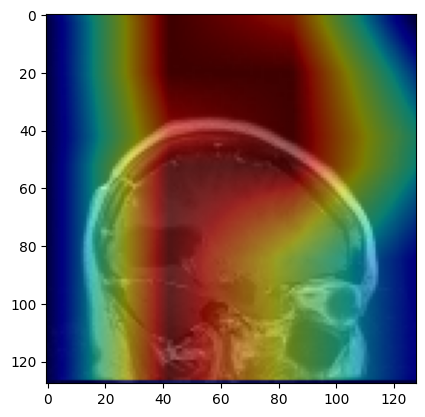

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step


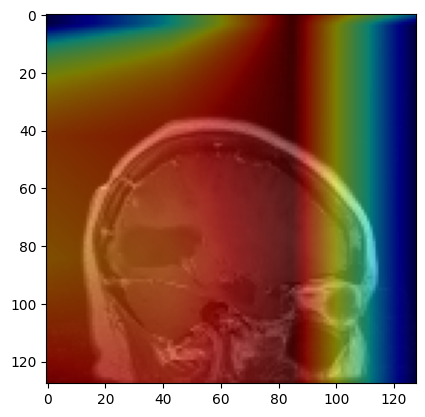

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step


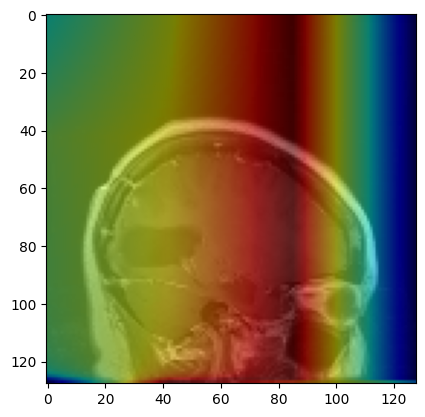

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step


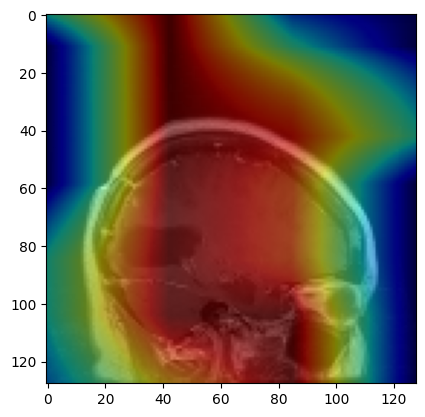

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step


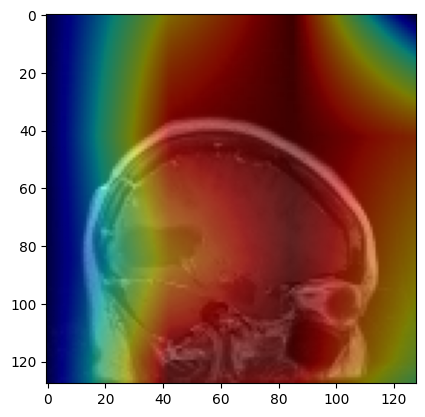

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step


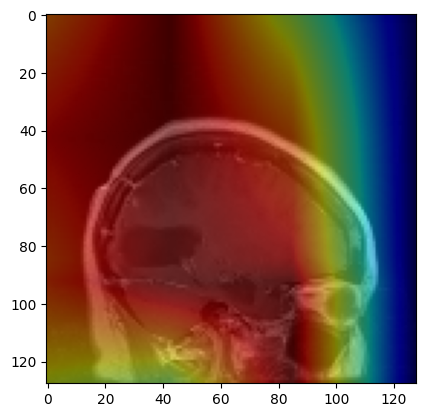

In [ ]:
# Install tf-keras-vis if not already installed
!pip install tf-keras-vis

from tf_keras_vis.gradcam import Gradcam
from tf_keras_vis.utils import normalize
import matplotlib.cm as cm

gradcam = Gradcam(model, clone=True)
# Select an image from test set
for i in range(30):
  image = X_test[i]
  image = np.expand_dims(image, axis=0)

# **Define the score function**
# Assuming you want to visualize the heatmap for the predicted class:
  score = model.predict(image)
# Get the predicted class index
  predicted_class = np.argmax(score)
# Define score function based on the predicted class
  def score_function(output):
    return output[:, predicted_class]

# Generate heatmap using the score function
  cam = gradcam(score_function, image, penultimate_layer=-1) #**Call gradcam with the score function instead of  score**
  heatmap = np.uint8(cm.jet(normalize(cam[0])) * 255)

  plt.imshow(X_test[0])
  plt.imshow(heatmap, alpha=0.5)
  plt.show()

In [ ]:
model.load_weights('best_model.keras')

In [ ]:
tf.keras.models.save_model(model, 'acc96.keras')

In [ ]:
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f'Test accuracy: {test_acc}')

27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - accuracy: 0.9734 - loss: 0.1664
Test accuracy: 0.9630952477455139
